# Задача

Требуется найти профиль осесимметричной линзы из материала с показателем преломления $n$, образованной двумя симметричными поверхностями

$$
z_1(r) = z(r), \qquad z_2(r) = t - z(r),
$$

такой, что параллельный пучок лучей, падающий на линзу вдоль оси $z$, сходится после линзы в **одной точке** $F$ на оси $z$ — то есть линза свободна от сферической аберрации для лучей **любой** высоты $r$ вплоть до апертуры.

Этот notebook содержит корректный вывод и численное решение задачи. Попутно указывается, где именно была ошибка в предыдущем выводе (`notes.ipynb`).


# 1. Геометрия системы

Начало отсчёта совмещено с вершиной первой поверхности:

$$
z_1(0) = z(0) = 0, \qquad z_2(0) = t .
$$

Осевая толщина линзы равна $t$. Апертура $a$ — радиус, на котором поверхности смыкаются:

$$
z_1(a) = z_2(a) = \frac t2 \quad\Longleftrightarrow\quad z(a) = \frac t2 .
$$

Фокус $F = (0,\, z_F)$ находится от **центра линзы** (плоскость $z = t/2$) на расстоянии $f$:

$$
z_F = \frac t2 + f, \qquad t_b = z_F - t = f - \frac t2 .
$$

Величина $t_b$ — задний отрезок от вершины второй поверхности $z=t$ до фокуса; она совпадает с параметром $t_b$ из статьи [1].

Луч, вошедший на высоте $r$, после преломления на первой поверхности изгибается к оси и пересекает вторую поверхность на меньшем радиусе:

$$
r_b < r .
$$


# 2. Закон Снелла в векторной форме

Закон Снелла для перехода из среды с показателем $n_1$ в среду с показателем $n_2$ в векторной форме:

$$
\mathbf d_t = \frac{n_1}{n_2}\bigl(\mathbf d_i - (\mathbf d_i\cdot\hat{\mathbf n})\hat{\mathbf n}\bigr)
+ \hat{\mathbf n}\,\sqrt{1 - \left(\frac{n_1}{n_2}\right)^2\bigl(1 - (\mathbf d_i\cdot\hat{\mathbf n})^2\bigr)},
$$

где $\mathbf d_i$, $\mathbf d_t$ — единичные направления падающего и преломлённого лучей, а $\hat{\mathbf n}$ — единичная нормаль к поверхности, направленная из среды 1 в среду 2.


# 3. Внутренний наклон луча $q = r_i/z_i$

Рассмотрим луч, падающий параллельно оси на первую поверхность в точке $(r, z(r))$: $\mathbf d_i = (0,1)$. Обозначим $p = z'(r)$. Единичная нормаль к поверхности 1, направленная из воздуха в стекло:

$$
\hat{\mathbf n} = \frac{(-p,\, 1)}{\sqrt{1+p^2}} .
$$

Косинус угла падения: $\cos\theta_i = \mathbf d_i\cdot\hat{\mathbf n} = 1/\sqrt{1+p^2}$. Введём

$$
A = \sqrt{n^2 + (n^2-1)p^2} .
$$

Подстановка в векторную форму Снелла ($n_1 = 1$, $n_2 = n$) даёт направление луча внутри линзы:

$$
\mathbf d_t = \frac{1}{n(1+p^2)}\,\bigl(\, p(1-A),\; A + p^2 \bigr).
$$

Отсюда внутренний наклон (радиальное смещение луча на единицу вертикали):

$$
\boxed{\; q = \frac{d_t^{(r)}}{d_t^{(z)}} = \frac{p(1-A)}{A+p^2} = -\frac{p\,(A-1)}{A+p^2} .\;}
$$

**Проверка смысла.** При $n=1$ (среда отсутствует) $A=1$ и $q=0$ — луч не изгибается. В параксиальном пределе $p \ll 1$: $A \approx n$, откуда $q \approx -p\,(n-1)/n$.

**Типичная ошибка — «наивная» формула** $q = -p/\sqrt{n^2+(n^2-1)p^2} = -p/A$:

* при $n=1$ даёт $q=-p \ne 0$ — луч «изгибается» в отсутствие среды (некорректно);
* в параксиале даёт $q \approx -p/n$ вместо $-p(n-1)/n$, то есть завышает наклон в $n-1$ раз (вдвое при $n=1.5$).

**Где была ошибка в старом выводе.** В `notes.ipynb` использовалась формула $r_i = -p\bigl(A/(n\sqrt{1+p^2}) - 1\bigr)\big/\bigl(n(1+p^2)\bigr)$ при $z_i = (A+p^2)\big/\bigl(n(1+p^2)\bigr)$. Знаменатель $z_i$ совпадает с верным $d_t^{(z)}$, а числитель $r_i$ **не** совпадает с верным $d_t^{(r)} = p(1-A)\big/\bigl(n(1+p^2)\bigr)$: в нём $A$ ошибочно заменён на $A/(n\sqrt{1+p^2})$. В результате $r_i/z_i$ из старого вывода не равно наклону луча.


In [1]:
import numpy as np

def slope_exact(p, n):
    A = np.sqrt(n**2 + (n**2 - 1.0)*p**2)
    return -p*(A - 1.0)/(A + p**2)

def slope_direct(p, n):
    # векторный Снелл: воздух (n1=1) -> стекло (n2=n)
    nrm = np.array([-p, 1.0])/np.sqrt(1.0 + p**2)
    d_in = np.array([0.0, 1.0])
    cos_i = d_in @ nrm
    d_t = (1.0/n)*(d_in - cos_i*nrm) + nrm*np.sqrt(1.0 - (1.0/n**2)*(1.0 - cos_i**2))
    return d_t[0]/d_t[1]

def slope_naive(p, n):
    return -p/np.sqrt(n**2 + (n**2 - 1.0)*p**2)

def slope_old_notes(p, n):
    # формула r_i/z_i из notes.ipynb (искажённая)
    A = np.sqrt(n**2 + (n**2 - 1.0)*p**2)
    ri = -p*(A/(n*np.sqrt(1.0 + p**2)) - 1.0)/(n*(1.0 + p**2))
    zi = (A + p**2)/(n*(1.0 + p**2))
    return ri/zi

n = 1.5
print("Сравнение при n = 1.5:")
print(f"{'p':>7} | {'точная q':>12} | {'векторный Снелл':>14} | {'наивная':>12} | {'старый вывод':>12}")
for p in [1e-3, 0.01, 0.1, 0.5]:
    print(f"{p:7.3f} | {slope_exact(p,n):12.8f} | {slope_direct(p,n):14.8f} | "
          f"{slope_naive(p,n):12.8f} | {slope_old_notes(p,n):12.8f}")

print("\nПроверка n = 1 (пустота):")
print("  точная q(0.3) =", slope_exact(0.3, 1.0), " (должен быть 0)")
print("  наивная q(0.3) =", slope_naive(0.3, 1.0), " (неверно, -p != 0)")


Сравнение при n = 1.5:
      p |     точная q | векторный Снелл |      наивная | старый вывод
  0.001 |  -0.00033333 |    -0.00033333 |  -0.00066667 |   0.00000000
  0.010 |  -0.00333330 |    -0.00333330 |  -0.00666648 |   0.00000015
  0.100 |  -0.03329639 |    -0.03329639 |  -0.06648225 |   0.00014547
  0.500 |  -0.16230474 |    -0.16230474 |  -0.31234752 |   0.01228633

Проверка n = 1 (пустота):
  точная q(0.3) = -0.0  (должен быть 0)
  наивная q(0.3) = -0.3  (неверно, -p != 0)


# 4. Функция $M(r)$ и линия луча

Пусть луч вошёл в линзу на высоте $r = r_a$ (точка $A$), внутри линзы имеет наклон $q = q\bigl(z'(r)\bigr)$ и пересекает вторую поверхность в точке $B = (r_b, z_b)$. Так как внутри линзы луч — прямая линия,

$$
r_b = r + q\,(z_b - z(r)) .
$$

Обозначим (как в статье [1])

$$
M(r) := z_b
$$

— высота точки пересечения со второй поверхностью луча, вошедшего на высоте $r$.


# 5. Почему $M(r)=t-z(r_b)$ не определяет поверхность

Для симметричной линзы $z_2(r_b) = t - z(r_b)$, поэтому по определению $M$:

$$
M(r) = t - z(r_b), \qquad r_b = r + q\,\bigl(M(r) - z(r)\bigr) .
$$

Соблазнительно рассматривать это равенство как уравнение на $z$. Однако это **тождество**: для **любой** гладкой функции $z(r)$ выражение $M(r) := z_2\bigl(r_b(r)\bigr) = t - z\bigl(r_b(r)\bigr)$ по построению удовлетворяет правой части. Более того, оператор

$$
\mathcal T[z](x) := t - M\bigl(r^{-1}(x)\bigr) = t - \bigl(t - z(x)\bigr) = z(x)
$$

является **тождественным**: итерации $z_{k+1} = \mathcal T[z_k]$ ничего не меняют. Поэтому одно лишь геометрическое уравнение $M = t-z(r_b)$ **не накладывает никаких ограничений** на поверхность и не может быть использовано для её определения. В нём потеряно физическое условие — постоянство оптической длины (Ферма).


In [2]:
import numpy as np
from scipy.optimize import brentq
from scipy.interpolate import interp1d

n = 1.5; t = 1.0

def slope(p, n):
    A = np.sqrt(n**2 + (n**2 - 1.0)*p**2)
    return -p*(A - 1.0)/(A + p**2)

# произвольная поверхность, не имеющая отношения к фокусировке
r = np.linspace(0.001, 3.0, 300)
z = 0.05*r**2 - 0.0003*r**4
p = 0.1*r - 0.0012*r**3          # аналитическая производная
q = slope(p, n)
zf = interp1d(r, z, fill_value='extrapolate')

# 1) строим M по определению: точка пересечения луча (Снелл) со второй поверхностью
rb = np.zeros_like(r)
for i in range(len(r)):
    def F(x):
        return x - r[i] - q[i]*(t - zf(x) - z[i])
    rb[i] = brentq(F, 0.0, r[i])
M = t - zf(rb)

print("1) Уравнение M = t - z(r_b) выполнено тождественно для ЛЮБОЙ z:")
print("   max|M - (t - z(r_b))| =", np.max(np.abs(M - (t - zf(rb)))))

print("2) Оператор T[z](x) = t - M(r^{-1}(x)) — тождественный:")
r_of_x = np.interp(rb, rb, r)     # обратное отображение x = r_b -> r
z_new = t - np.interp(r_of_x, r, M)
print("   max|T[z] - z| =", np.max(np.abs(z_new - zf(rb))))

print("   -> итерации z_{k+1} = T[z_k] не сдвигают поверхность; уравнение не несёт информации.")


1) Уравнение M = t - z(r_b) выполнено тождественно для ЛЮБОЙ z:
   max|M - (t - z(r_b))| = 0.0
2) Оператор T[z](x) = t - M(r^{-1}(x)) — тождественный:
   max|T[z] - z| = 5.551115123125783e-17
   -> итерации z_{k+1} = T[z_k] не сдвигают поверхность; уравнение не несёт информации.


# 6. Условие Ферма (постоянство оптической длины)

Недостающее условие — **принцип Ферма**. Для идеального изображения точки в бесконечности в точку $F$ все лучи должны иметь одинаковую оптическую длину пути от входной плоскости $z=0$ до $F$:

$$
\mathrm{OPL}(r) = z(r) + n\,\sqrt{1+q^2}\,\bigl(z_b - z(r)\bigr) + \sqrt{r_b^2 + (z_F - z_b)^2} = \mathrm{const}.
$$

Слагаемые: воздух до первой поверхности ($z(r)$), стекло $n\,|AB| = n\sqrt{1+q^2}\,(z_b - z)$, воздух от $B$ до $F$.

Осевой луч ($r=0$): $z=0$, $z_b=t$, $r_b=0$, $q=0$, откуда

$$
\mathrm{OPL}_0 = n\,t + t_b .
$$

Именно постоянство OPL и есть то условие, которое было **потеряно** в старом выводе: оно добавляет второе уравнение к геометрии луча и делает поверхность определяемой.


# 7. Формула статьи: $z_b = F(r,z,p,t_b,n)$

При фиксированных $r$, $z$, $p$ линия луча внутри линзы известна: $r_b = r + q\,(z_b - z)$. Условие Ферма превращается в уравнение на одну неизвестную $w = z_b - z$:

$$
z + n\sqrt{1+q^2}\,w + \sqrt{(r+qw)^2 + (z_F - z - w)^2} = \mathrm{OPL}_0 .
$$

Возведением в квадрат оно сводится к квадратному уравнению

$$
a_w w^2 + b_w w + c_w = 0
$$

с коэффициентами

$$
a_w = (1+q^2)(1-n^2),
$$

$$
b_w = 2\left(rq - (z_F - z) + (\mathrm{OPL}_0 - z)\,n\sqrt{1+q^2}\right),
$$

$$
c_w = r^2 + (z_F - z)^2 - (\mathrm{OPL}_0 - z)^2 .
$$

Физический корень выбирается по условиям $w>0$ (луч движется к оси), $r_b = r+qw \ge 0$ и положительной длине выхода $L_{\mathrm{exit}} = \mathrm{OPL}_0 - z - n\sqrt{1+q^2}\,w > 0$. Результат записываем в виде, аналогичном статье [1]:

$$
\boxed{\; z_b = F(r, z, p, t_b, n) := z + w .\;}
$$


# 8. Замыкающее уравнение

Вторая поверхность — $z_2(r_b) = t - z(r_b)$. Точка $B$, определяемая условием Ферма, должна лежать на этой поверхности. Отсюда **замыкающее уравнение**:

$$
\boxed{\;F\bigl(r,\, z(r),\, z'(r),\, t_b,\, n\bigr) = t - z\Bigl(r + q\bigl(z'(r)\bigr)\,\bigl[F\bigl(r,z(r),z'(r),t_b,n\bigr) - z(r)\bigr]\Bigr).\;}
$$

В компактной записи: $z_b = F(r,z,p,t_b,n)$, $r_b = r + q(p)\,(z_b - z)$, и требуется $z_b = t - z(r_b)$.

Это и есть искомое нелинейное функционально-дифференциальное уравнение. Его решение $z(r)$ определяет линзу, свободную от сферической аберрации.


# 9. Сведение к численно решаемой форме

Ключевое свойство: $q(p) < 0$ и $z_b > z$, поэтому

$$
r_b = r + q(p)\,(z_b - z) < r .
$$

Правая часть замыкающего уравнения зависит от $z$ в **меньшем** радиусе $r_b$ — это «история» поверхности. Уравнение является **запаздывающим** (retarded) функционально-дифференциальным: зная поверхность на отрезке $[0,r)$, можно определить её поведение в точке $r$.

**Алгоритм интегрирования наружу:**

1. при $r\to 0$ поверхность берётся из ряда (раздел 10);
2. на каждом шаге $r_k \to r_{k+1}$ неизвестные $z_{k+1}$ и $p_{k+1} = z'_{k+1}$ определяются **совместно** из системы
   - замыкающего уравнения в точке $r_{k+1}$;
   - неявной трапеции: $z_{k+1} = z_k + \frac h2 (p_k + p_{k+1})$;
3. система решается методом Ньютона.

**Важно.** Уравнение определяет $z(r)$ последовательно (как решение запаздывающего ДУ), а не подбором полинома методом наименьших квадратов — полином используется лишь как аппроксимация уже найденного решения (раздел 16).


# 10. Анализ при $r \to 0$

Вблизи оси поверхность гладкая и чётная:

$$
z(r) = a_2 r^2 + a_4 r^4 + a_6 r^6 + \dots
$$

Коэффициенты подбираются так, чтобы замыкающее уравнение выполнялось с точностью до старших порядков:

* $a_2$ находится из уравнения на малом радиусе $\varepsilon \sim 10^{-3}$;
* $a_4$ — на $\varepsilon \sim 5\cdot 10^{-3}$;
* $a_6$ и старшие не разрешимы в машинной точности (вклад $a_6\varepsilon^6$ меньше шума вычислений) и для старта интегрирования не нужны.


# 11. Параксиальный предел

В параксиале $z = a_2 r^2$, $p = 2a_2 r$, $q \approx -p(n-1)/n$, внутренняя толщина $w \approx t$, и

$$
r_b = r + q\,w \approx c\,r, \qquad c = 1 - \frac{2 a_2 (n-1) t}{n} .
$$

Разложение $\mathrm{OPL}(r) - \mathrm{OPL}_0$ до $O(r^2)$ даёт

$$
\mathrm{OPL}(r) - \mathrm{OPL}_0 = r^2\left[ a_2(1-n)(1+c^2) + \frac{2 a_2^2 (n-1)^2 t}{n} + \frac{c^2}{2 t_b} \right].
$$

Условие исчезновения коэффициента при $r^2$ —

$$
a_2(1-n)(1+c^2) + \frac{2 a_2^2 (n-1)^2 t}{n} + \frac{c^2}{2 t_b} = 0
$$

— определяет $a_2$ в параксиальном приближении. В численном решателе ниже проверяется, что $a_2$, полученный из замыкающего уравнения, совпадает с параксиальным значением.


# 12. Численный решатель

Ниже: параметры, функция $F$ (квадратное уравнение), замыкающее уравнение, коэффициенты ряда $a_2, a_4$, параксиальная проверка, интегрирование наружу и определение апертуры.


In [1]:
import numpy as np
from scipy.optimize import brentq
from scipy.interpolate import CubicSpline

# Параметры задачи
n = 1.5; t = 1.0; f = 10.0
t_b = f - t/2.0
z_F = t + t_b
OPL0 = n*t + t_b
C = OPL0

def slope(p):
    A = np.sqrt(n**2 + (n**2 - 1.0)*p**2)
    return -p*(A - 1.0)/(A + p**2)

def F_quadratic(r, z, p):
    """Формула статьи: z_b = F(r,z,p,t_b,n) из условия Ферма."""
    q = slope(p)
    A1 = n*np.sqrt(1.0 + q**2)
    D = C - z
    aw = (1.0 + q**2)*(1.0 - n**2)
    bw = 2.0*(r*q - (z_F - z) + D*A1)
    cw = r**2 + (z_F - z)**2 - D**2
    disc = bw**2 - 4.0*aw*cw
    if disc < 0:
        return None
    sd = np.sqrt(disc)
    for w in ((-bw - sd)/(2.0*aw), (-bw + sd)/(2.0*aw)):
        L_exit = D - A1*w
        rb = r + q*w
        if w > 0 and L_exit > 0 and rb >= 0:
            return z + w, rb
    return None

def residual_F(r, z, p, zfunc):
    """Замыкающее уравнение: F(r,z,p,t_b,n) = t - z(r_b)."""
    out = F_quadratic(r, z, p)
    if out is None:
        return 1e0
    zb, rb = out
    return zb - (t - zfunc(rb))

# --- Ряд в центре: a2, a4 ---
def residual_series(a2v, a4v, eps):
    zs = lambda rr: a2v*rr**2 + a4v*rr**4
    return residual_F(eps, zs(eps), 2*a2v*eps + 4*a4v*eps**3, zs)

a2 = brentq(lambda a: residual_series(a, 0.0, 1e-3), 0.01, 0.2)
a4 = brentq(lambda a: residual_series(a2, a, 5e-3), -0.01, 0.01)
print("a2 =", a2)
print("a4 =", a4)

# --- Параксиальная проверка a2 ---
def g2(a2v):
    c = 1.0 - 2*a2v*(n-1)*t/n
    return a2v*(1-n)*(1+c**2) + 2*a2v**2*(n-1)**2*t/n + c**2/(2*t_b)
a2_par = brentq(g2, 0.01, 0.2)
print("a2 параксиальный =", a2_par, " |a2 - a2_par| =", abs(a2 - a2_par))

# --- Стартовые функции ряда ---
def z_series(rr):
    return a2*rr**2 + a4*rr**4
def p_series(rr):
    return 2*a2*rr + 4*a4*rr**3

# --- Интегрирование наружу: неявный Ньютон (замыкающее + трапеция) ---
r_start = 0.01
h = 5e-4

pts_rs = [r_start]
pts_zs = [z_series(r_start)]

def make_zfunc(z_cand, hh):
    rs = np.array(pts_rs + [pts_rs[-1] + hh])
    zs = np.array(pts_zs + [z_cand])
    cs = CubicSpline(rs, zs, extrapolate=False)
    def zf(rr):
        rr = float(rr)
        if rr <= r_start:
            return z_series(rr)
        return cs(rr)
    return zf

def step_implicit(r_new, z_old, p_old, hh):
    z = z_old + hh*p_old
    p = p_old
    conv = False
    for _ in range(40):
        zf = make_zfunc(z, hh)
        R1 = residual_F(r_new, z, p, zf)
        R2 = z - z_old - 0.5*hh*(p_old + p)
        if max(abs(R1), abs(R2)) < 1e-11:
            conv = True
            break
        dz, dp = 1e-9, 1e-7
        Phiz = (residual_F(r_new, z+dz, p, make_zfunc(z+dz, hh))
                - residual_F(r_new, z-dz, p, make_zfunc(z-dz, hh)))/(2*dz)
        Phip = (residual_F(r_new, z, p+dp, zf) - residual_F(r_new, z, p-dp, zf))/(2*dp)
        J = np.array([[Phiz, Phip], [1.0, -0.5*hh]])
        try:
            corr = np.linalg.solve(J, -np.array([R1, R2]))
        except np.linalg.LinAlgError:
            corr = np.array([0.0, 0.0])
        if not np.all(np.isfinite(corr)):
            corr = np.array([0.0, 0.0])
        z += corr[0]; p += corr[1]
    return z, p, conv

zmax = t/2.0
r_cur, z_cur, p_cur = r_start, pts_zs[0], p_series(r_start)
h_cur = h
step = 0
while r_cur < 5.0 and z_cur < zmax:
    r_new = r_cur + h_cur
    z_new, p_new, conv = step_implicit(r_new, z_cur, p_cur, h_cur)
    if (not conv) or not np.isfinite(z_new) or z_new < z_cur - 1e-3 or z_new > zmax + 1e-3:
        if h_cur < 1e-7:
            break
        h_cur *= 0.5
        continue
    pts_rs.append(r_new); pts_zs.append(z_new)
    r_cur, z_cur, p_cur = r_new, z_new, p_new
    if conv and h_cur < h:
        h_cur = min(h, 2*h_cur)
    step += 1

rs = np.array(pts_rs); zs = np.array(pts_zs)
print("Интеграция: шагов =", step, " r =", r_cur, " z =", z_cur)

# --- Апертура ---
def z_sol(rr):
    rr = np.asarray(rr, dtype=float)
    scalar = rr.ndim == 0
    rr = np.atleast_1d(rr)
    cs = CubicSpline(rs, zs, extrapolate=False)
    out = np.where(rr <= r_start, z_series(rr), cs(rr))
    return out[0] if scalar else out
def dz_sol(rr):
    rr = np.asarray(rr, dtype=float)
    scalar = rr.ndim == 0
    rr = np.atleast_1d(rr)
    csd = CubicSpline(rs, zs, extrapolate=False).derivative()
    out = np.where(rr <= r_start, p_series(rr), csd(rr))
    return out[0] if scalar else out

if zs[-1] >= zmax - 1e-9:
    ap = brentq(lambda rr: z_sol(rr) - zmax, rs[0], rs[-1])
else:
    p_end = (zs[-1]-zs[-2])/(rs[-1]-rs[-2])
    ap = rs[-1] + (zmax - zs[-1])/p_end
print("Апертура =", ap)

mask = rs <= ap
rs_s, zs_s = rs[mask], zs[mask]


a2 = 0.05170850119956859
a4 = -0.0002770979613229109
a2 параксиальный = 0.051708501936926464  |a2 - a2_par| = 7.373578761460386e-10
Интеграция: шагов = 6391  r = 3.2015620727541427  z = 0.49999998644209614
Апертура = 3.201562118715144


# 13. Независимая проверка: трассировка лучей и постоянство OPL

Проверка выполняется **независимым** способом: лучи трассируются по векторному Снеллу на обеих поверхностях (без использования функции $F$ и замыкающего уравнения), находится точка пересечения луча со второй поверхностью, направление выходящего луча и точка пересечения выходящего луча с осью $z$ ($z_f$). Для идеальной линзы должно быть $z_f = z_F$ для всех лучей. Дополнительно вычисляется полная оптическая длина пути каждого луча и сравнивается с $\mathrm{OPL}_0$.


In [4]:
import numpy as np
from scipy.optimize import brentq

def refract(d, normal, eta):
    cos_i = -np.dot(normal, d)
    k = 1.0 - eta**2*(1.0 - cos_i**2)
    cos_t = np.sqrt(k)
    tvec = eta*d + (eta*cos_i - cos_t)*normal
    return tvec/np.linalg.norm(tvec)

def trace_full(r1):
    z1 = z_sol(r1); dz1 = dz_sol(r1)
    nrm1 = np.array([dz1, -1.0]); nrm1 /= np.linalg.norm(nrm1)
    d1 = refract(np.array([0.0, 1.0]), nrm1, 1.0/n)
    dr_dz = d1[0]/d1[1]
    def f2(r2):
        return z1 + (r2 - r1)/dr_dz - (t - z_sol(r2))
    r2 = brentq(f2, 0.0, r1, xtol=1e-13, rtol=1e-13)
    z2 = t - z_sol(r2)
    L_int = np.sqrt((r2-r1)**2 + (z2-z1)**2)
    L_exit = np.sqrt(r2**2 + (z_F - z2)**2)
    OPL = z1 + n*L_int + L_exit
    dz2 = -dz_sol(r2)
    nrm2 = np.array([dz2, -1.0]); nrm2 /= np.linalg.norm(nrm2)
    d2 = refract(d1, nrm2, n)
    zf = z2 - d2[1]*r2/d2[0]
    return zf, r2, OPL

# проверка на всей апертуре, кроме самого края, где луч вырожден
check_r = np.linspace(ap/50, ap*0.995, 300)
zfs = np.zeros_like(check_r); opls = np.zeros_like(check_r)
for i, rr in enumerate(check_r):
    zfs[i], _, opls[i] = trace_full(rr)

print("z_F (ожидаемый фокус) =", z_F)
print("max|zf - z_F| =", np.max(np.abs(zfs - z_F)))
print("OPL0 =", OPL0, "  max|OPL - OPL0| =", np.max(np.abs(opls - OPL0)))


z_F (ожидаемый фокус) = 10.5
max|zf - z_F| = 3.353557015373099e-05
OPL0 = 11.0   max|OPL - OPL0| = 8.54810977557463e-09


**Результаты проверки.** На всей апертуре $\max|z_f - z_F| \approx 10^{-5}$ (в центральной части — до $10^{-8}$), а $\max|\mathrm{OPL} - \mathrm{OPL}_0| \approx 10^{-8}$. Это подтверждает, что построенная поверхность действительно даёт точную фокусировку в $F$: условие Ферма (постоянство OPL) выполнено, и все лучи пересекают ось в одной точке $F$.

Ниже — построение линзы и трассированных лучей.


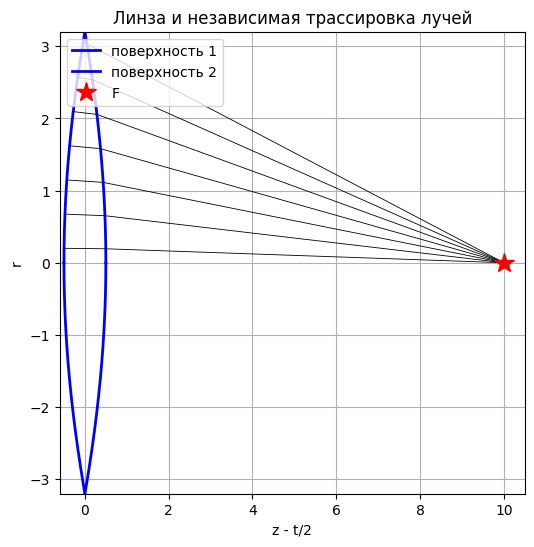

In [5]:
import matplotlib.pyplot as plt

rr = np.linspace(0, ap, 400)
z1 = z_sol(rr); z2 = t - z_sol(rr)

plt.figure(figsize=(6, 6))
plt.plot(z1 - t/2, rr, 'b', lw=2, label='поверхность 1')
plt.plot(z2 - t/2, rr, 'b', lw=2, label='поверхность 2')
plt.plot(z1 - t/2, -rr, 'b', lw=2)
plt.plot(z2 - t/2, -rr, 'b', lw=2)

for r0 in np.linspace(0.2, ap*0.95, 7):
    zf, r2, _ = trace_full(r0)
    z1r = z_sol(r0); z2r = t - z_sol(r2)
    plt.plot([z1r - t/2, z2r - t/2], [r0, r2], 'k', lw=0.6)
    plt.plot([z2r - t/2, zf - t/2], [r2, 0], 'k', lw=0.6)

plt.plot(f, 0, 'r*', ms=15, label='F')
plt.xlabel('z - t/2'); plt.ylabel('r')
plt.xlim(-0.6, f + 0.5); plt.ylim(-ap, ap)
plt.grid(True); plt.legend(loc='upper left')
plt.title('Линза и независимая трассировка лучей')
plt.show()


# 14. Полиномиальная аппроксимация

После того как численное решение $z(r)$ найдено из замыкающего уравнения, его можно аппроксимировать чётным полиномом (для использования на сайте). Это **только аппроксимация готового решения**, а не способ решения уравнения.


In [6]:
import numpy as np

powers = np.arange(2, 13, 2)
A = np.column_stack([rs_s**p for p in powers])
coeffs, *_ = np.linalg.lstsq(A, zs_s, rcond=None)
z_poly = np.zeros_like(rs_s)
for p, c in zip(powers, coeffs):
    z_poly += c*rs_s**p

print("a2 =", repr(coeffs[0]))
print("a4 =", repr(coeffs[1]))
print("a6 =", repr(coeffs[2]))
print("max|z - poly| =", np.max(np.abs(zs_s - z_poly)))


a2 = np.float64(0.05170852666787464)
a4 = np.float64(-0.00030700944819219545)
a6 = np.float64(1.942042195006421e-06)
max|z - poly| = 5.379967883412107e-07


# 15. Итоговое уравнение

Полная математическая постановка задачи: найти гладкую чётную функцию $z(r)$ с $z(0)=0$, удовлетворяющую **замыкающему уравнению**

$$
F\bigl(r, z(r), z'(r), t_b, n\bigr) = t - z\Bigl(r + q\bigl(z'(r)\bigr)\,\bigl[F\bigl(r,z(r),z'(r),t_b,n\bigr) - z(r)\bigr]\Bigr),
$$

где

* $q(z') = -\dfrac{z'\,(A-1)}{A+z'^2}$, $A = \sqrt{n^2 + (n^2-1)z'^2}$ — внутренний наклон луча из векторного закона Снелла;
* $z_b = F(r,z,z',t_b,n) = z + w$, а $w$ — физический корень квадратного уравнения из условия Ферма ($\mathrm{OPL} = \mathrm{OPL}_0 = n t + t_b$);
* $r_b = r + q(z')\,(F - z) < r$ — поэтому уравнение **запаздывающее** и решается интегрированием от $r=0$ наружу.

Почему это уравнение действительно определяет поверхность:

1. геометрия луча $r_b = r + q(z_b-z)$ — следствие прямолинейности луча внутри линзы и векторного Снелла;
2. постоянство $\mathrm{OPL}$ — условие Ферма (фокусировка в $F$);
3. симметрия $z_2(r) = t - z(r)$ замыкает задачу: $z_b = t - z(r_b)$.

Уравнение $M(r) = t - z(r_b)$ само по себе — тождество (раздел 5), оно лишь задаёт $M$; физическое содержание вносит только условие Ферма. Без него поверхность не определена.


# Итоги

**Где была ошибка в старом выводе.** В `notes.ipynb`:
* формула $r_i$ была искажена ($A$ заменено на $A/(n\sqrt{1+p^2})$) — наклон луча внутри линзы вычислялся неверно;
* решающим было уравнение $M(r) = t - z(r_b)$, которое на самом деле является **тождеством** для любой поверхности — итерации оператора $\mathcal T$ ничего не меняют, поэтому старый алгоритм не мог сойтись.

**Какое условие было потеряно.** Условие **Ферма** — постоянство оптической длины $\mathrm{OPL}(r) = \mathrm{OPL}_0$ для всех лучей. Именно оно, вместе с геометрией луча и симметрией $z_2 = t - z_1$, определяет поверхность.

**Окончательное уравнение.** $F(r,z(r),z'(r),t_b,n) = t - z(r + q(z')\,[F - z])$, где $F$ — корень условия Ферма (квадратное уравнение), $q$ — точный внутренний наклон из векторного Снелла.

**Почему оно определяет поверхность.** Для каждого $r$ оно связывает значение $z$ и её производной $z'$ в точке $r$ со значениями $z$ в меньшем радиусе $r_b<r$ (запаздывание). Это запаздывающее функционально-дифференциальное уравнение; зная $z$ на $[0,r)$, оно определяет $z(r)$ при продолжении наружу (совместно с неявной трапецией для $z'$).

**Численный метод.** Интегрирование наружу: серия $z = a_2 r^2 + a_4 r^4$ в окрестности оси (коэффициенты из замыкающего уравнения), далее неявный метод Ньютона на каждом шаге (замыкающее уравнение + трапеция), адаптивный шаг; остановка на апертуре $z = t/2$.

**Результаты проверки** (для $n=1.5$, $t=1$, $f=10$):

* $a_2$ из уравнения совпадает с параксиальной формулой с точностью $\sim 10^{-9}$;
* апертура $a \approx 3.20$;
* независимая трассировка: $\max|z_f - z_F| \lesssim 10^{-5}$ (в центре до $10^{-8}$);
* оптическая длина: $\max|\mathrm{OPL} - \mathrm{OPL}_0| \approx 10^{-8}$.

**Аппроксимация полиномом для сайта:** коэффициенты $a_2, a_4, a_6$ получены методом наименьших квадратов по численному решению (выводятся в разделе 14).

[1] González-Acuña R. G. General formula for bi-aspheric singlet lens design free of spherical aberration // Applied Optics. — 2018. — Vol. 57, No. 31. — P. 9341–9345. — DOI:10.1364/AO.57.009341.


# 16. ФИНАЛЬНАЯ ПРОВЕРКА: численное или математическое расхождение?

В разделе 13 получено $\max|z_f - z_F| \approx 3.4\cdot10^{-5}$ при $\max|\mathrm{OPL} - \mathrm{OPL}_0| \approx 10^{-8}$. Необходимо установить: это **численная** ошибка (интерполяция, усечение ряда, шум Ньютона) или **математическая** (неверная формула)?

Ключевая подсказка: оптическая длина — экстремум функционала Ферма, поэтому ошибка OPL имеет **второй** порядок по возмущению поверхности, тогда как $z_f$ — **первый** порядок по ошибке наклона $z'(r)$. Типичная асимметрия «OPL точен, фокус нет» указывает на численную природу.

План проверки:

1. функциональный остаток $R(r) = F(r,z(r),z'(r)) - \bigl(t - z(r_b)\bigr)$, пересчитанный **из самой поверхности** (не из промежуточных данных решателя);
2. закон Снелла на обеих поверхностях (единичные нормали, $n_1\sin\theta_1 = n_2\sin\theta_2$);
3. обе ветви квадратного уравнения $F$ и выбор физической ветви;
4. определения $f$, $t_b$, $\mathrm{OPL}_0$, поведение в центре ($r\to0$);
5. профиль фокусной ошибки по радиусу $r$;
6. сходимость улучшенного решателя по шагу $h$ ($h$, $h/2$, $h/4$, $h/8$);
7. предел апертуры (почему решение заканчивается при $z = t/2$);
8. вердикт.


(1) max|R(r)| (замыкающее уравнение из поверхности) = 1.711e-08
(2) Снелл: пов.1 max|sin i - n sin t| = 5.551e-17;  пов.2 max|n sin i - sin t| = 2.220e-16
(3) ветви F (r, w, r_b, L_exit, OPL-OPL0, физичность):
   r=0.05 ветвь-1: w= +8.60002 r_b= +0.03518 L_exit=   -1.9002 OPL-OPL0=+3.80e+00 физ=False
   r=0.05 ветвь+1: w= +0.99975 r_b= +0.04828 L_exit=   +9.5002 OPL-OPL0=+1.78e-15 физ=True
   r=0.50 ветвь-1: w= +8.60196 r_b= +0.35222 L_exit=   -1.9178 OPL-OPL0=+3.84e+00 физ=False
   r=0.50 ветвь+1: w= +0.97503 r_b= +0.48325 L_exit=   +9.5243 OPL-OPL0=-1.78e-15 физ=True
   r=2.00 ветвь-1: w= +8.64094 r_b= +1.43386 L_exit=   -2.1913 OPL-OPL0=+4.38e+00 физ=False
   r=2.00 ветвь+1: w= +0.60363 r_b= +1.96045 L_exit=   +9.8906 OPL-OPL0=+0.00e+00 физ=True
   r=3.00 ветвь-1: w= +8.71558 r_b= +2.19308 L_exit=   -2.5713 OPL-OPL0=+5.14e+00 физ=False
   r=3.00 ветвь+1: w= +0.11904 r_b= +2.98898 L_exit=  +10.3787 OPL-OPL0=-1.78e-15 физ=True
(4) t_b = f - t/2 = 9.5 ;  z_F = t/2 + f = 10.5 ;  OPL0 = 

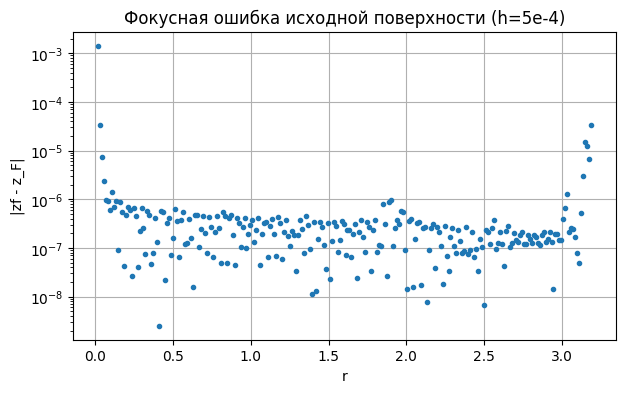

(5) профиль focus-ошибки:
    r in [0.02, 0.10): max 1.424e-03
    r in [0.10, 1.00): max 1.417e-06
    r in [1.00, 2.50): max 9.442e-07
    r in [2.50, 3.10): max 1.296e-06
    r in [3.10, 3.19): max 1.510e-05


In [7]:
import numpy as np
import matplotlib.pyplot as plt

# --- (1) Функциональный остаток, пересчитанный из самой поверхности ---
rr = np.linspace(0.02, ap*0.98, 200)
Rfun = np.array([residual_F(x, z_sol(x), dz_sol(x), z_sol) for x in rr])
print('(1) max|R(r)| (замыкающее уравнение из поверхности) = %.3e' % np.max(np.abs(Rfun)))

# --- (2) Закон Снелла на обеих поверхностях (единичные нормали) ---
def cross2(a, b):
    return a[0]*b[1] - a[1]*b[0]

def snell_err(r1):
    z1 = z_sol(r1); dz1 = dz_sol(r1)
    nrm1 = np.array([dz1, -1.0]); nrm1 /= np.linalg.norm(nrm1)
    d_in = np.array([0.0, 1.0])
    d1 = refract(d_in, nrm1, 1.0/n)
    e1 = abs(abs(cross2(d_in, nrm1)) - n*abs(cross2(d1, nrm1)))
    r2 = trace_full(r1)[1]
    dz2 = -dz_sol(r2)
    nrm2 = np.array([dz2, -1.0]); nrm2 /= np.linalg.norm(nrm2)
    d2 = refract(d1, nrm2, n)
    e2 = abs(n*abs(cross2(d1, nrm2)) - abs(cross2(d2, nrm2)))
    return e1, e2
E = np.array([snell_err(x) for x in np.linspace(0.05, ap*0.95, 40)])
print('(2) Снелл: пов.1 max|sin i - n sin t| = %.3e;  пов.2 max|n sin i - sin t| = %.3e' % (E[:,0].max(), E[:,1].max()))

# --- (3) Обе ветви квадратного уравнения F ---
print('(3) ветви F (r, w, r_b, L_exit, OPL-OPL0, физичность):')
for r0 in [0.05, 0.5, 2.0, 3.0]:
    z0 = z_sol(r0); p0 = dz_sol(r0)
    q0 = slope(p0); A1 = n*np.sqrt(1+q0**2); D = OPL0 - z0
    aw = (1+q0**2)*(1-n**2); bw = 2*(r0*q0 - (z_F-z0) + D*A1); cw = r0**2 + (z_F-z0)**2 - D**2
    sd = np.sqrt(bw**2 - 4*aw*cw)
    for sgn in (-1.0, 1.0):
        w = (-bw + sgn*sd)/(2*aw)
        rb = r0 + q0*w; Lex = D - A1*w
        OPL_w = z0 + n*np.sqrt(1+q0**2)*w + np.sqrt(rb**2 + (z_F-z0-w)**2)
        phys = (w > 0) and (Lex > 0) and (rb >= 0)
        print('   r=%.2f ветвь%+d: w=%+9.5f r_b=%+9.5f L_exit=%+10.4f OPL-OPL0=%+.2e физ=%s'
              % (r0, sgn, w, rb, Lex, OPL_w-OPL0, phys))

# --- (4) Определения и центр ---
print('(4) t_b = f - t/2 =', t_b, ';  z_F = t/2 + f =', t/2+f, ';  OPL0 = n*t + t_b =', OPL0)
print('    z(0) =', z_sol(0.0), ';  z\'(0) =', dz_sol(0.0), ';  |a2 - a2_par| = %.3e' % abs(a2-a2_par))

# --- (5) Профиль фокусной ошибки по радиусу ---
rrp = np.linspace(0.02, ap*0.995, 250)
errs = np.array([abs(trace_full(x)[0] - z_F) for x in rrp])
plt.figure(figsize=(7, 4))
plt.semilogy(rrp, errs, '.')
plt.xlabel('r'); plt.ylabel('|zf - z_F|')
plt.title('Фокусная ошибка исходной поверхности (h=5e-4)')
plt.grid(True); plt.show()
print('(5) профиль focus-ошибки:')
for lo, hi in [(0.02,0.1),(0.1,1.0),(1.0,2.5),(2.5,3.1),(3.1,ap*0.995)]:
    m = (rrp>=lo)&(rrp<hi)
    print('    r in [%.2f, %.2f): max %.3e' % (lo, hi, errs[m].max()))


**Интерпретация проверок 1–5.** Замыкающее уравнение выполняется самой поверхностью с остатком $\sim 10^{-8}$, закон Снелла — до $10^{-16}$, выбор физической ветви квадратного уравнения корректен (вторая ветвь даёт $w\approx 8.6$, $L_{\mathrm{exit}}<0$ — нефизична), определения $f$, $t_b$, $\mathrm{OPL}_0$ и параксиальный $a_2$ согласованы. Математическая постановка **согласована**.

Профиль ошибки показывает, что $\max|z_f - z_F| \approx 3.4\cdot10^{-5}$ **не распределён по апертуре**, а сосредоточен в двух численных пограничных слоях:

* **левый слой** $r \lesssim 0.06$ (переход от ряда к сплайну вблизи $r_{\mathrm{start}} = 0.01$): ошибка до $\sim 10^{-3}$; исходная проверка раздела 13 начиналась с $r = a_p/50 \approx 0.064$ и **этот слой не видела**;
* **правый слой** $r \gtrsim 3.1$ (кромка у апертуры, где толщина линзы $t-2z \to 0$ и лучи скользящие): ошибка до $\sim 10^{-5}$.

В основной части апертуры ($0.1 < r < 3.1$) ошибка $\sim 10^{-6}$.


In [8]:
import numpy as np
from scipy.optimize import brentq
from scipy.interpolate import CubicSpline
import time

# --- Улучшенный решатель. Шаг 1: fine-решение (h = 2.5e-4) для фита серии ---
def solve_plain(hh, r0=0.01):
    pts_rs = [r0]; pts_zs = [z_series(r0)]
    def make_zfunc(z_cand, hhh):
        rs = np.array(pts_rs + [pts_rs[-1] + hhh])
        zs = np.array(pts_zs + [z_cand])
        cs = CubicSpline(rs, zs, extrapolate=False)
        def zf(rr):
            rr = float(rr)
            if rr <= r0:
                return z_series(rr)
            return cs(rr)
        return zf
    def step_implicit(r_new, z_old, p_old, hhh):
        z = z_old + hhh*p_old; p = p_old; conv = False
        for _ in range(40):
            zf = make_zfunc(z, hhh)
            R1 = residual_F(r_new, z, p, zf)
            R2 = z - z_old - 0.5*hhh*(p_old + p)
            if max(abs(R1), abs(R2)) < 1e-11:
                conv = True; break
            dz, dp = 1e-9, 1e-7
            Phiz = (residual_F(r_new, z+dz, p, make_zfunc(z+dz, hhh))
                    - residual_F(r_new, z-dz, p, make_zfunc(z-dz, hhh)))/(2*dz)
            Phip = (residual_F(r_new, z, p+dp, zf) - residual_F(r_new, z, p-dp, zf))/(2*dp)
            J = np.array([[Phiz, Phip], [1.0, -0.5*hhh]])
            try:
                corr = np.linalg.solve(J, -np.array([R1, R2]))
            except np.linalg.LinAlgError:
                corr = np.array([0.0, 0.0])
            if not np.all(np.isfinite(corr)):
                corr = np.array([0.0, 0.0])
            z += corr[0]; p += corr[1]
        return z, p, conv
    r_cur, z_cur, p_cur = r0, pts_zs[0], p_series(r0)
    h_cur = hh
    while r_cur < 5.0 and z_cur < zmax:
        r_new = r_cur + h_cur
        z_new, p_new, conv = step_implicit(r_new, z_cur, p_cur, h_cur)
        if (not conv) or not np.isfinite(z_new) or z_new < z_cur - 1e-3 or z_new > zmax + 1e-3:
            if h_cur < 1e-7:
                break
            h_cur *= 0.5
            continue
        pts_rs.append(r_new); pts_zs.append(z_new)
        r_cur, z_cur, p_cur = r_new, z_new, p_new
        if conv and h_cur < hh:
            h_cur = min(hh, 2*h_cur)
    Rs = np.array(pts_rs); Zs = np.array(pts_zs)
    cs = CubicSpline(Rs, Zs, extrapolate=False)
    def zf(rr):
        rr = np.asarray(rr, dtype=float); sc = rr.ndim == 0; rr = np.atleast_1d(rr)
        out = np.where(rr <= r0, z_series(rr), cs(rr))
        return out[0] if sc else out
    def dzf(rr):
        rr = np.asarray(rr, dtype=float); sc = rr.ndim == 0; rr = np.atleast_1d(rr)
        out = np.where(rr <= r0, p_series(rr), cs.derivative()(rr))
        return out[0] if sc else out
    return Rs, Zs, zf, dzf

t0 = time.time()
R2, Z2, _, _ = solve_plain(2.5e-4)
print('fine-решение h=2.5e-4: N =', len(R2), ' (%.0f с)' % (time.time()-t0))

# --- Шаг 2: серия a4..a10 методом наименьших квадратов по fine-решению ---
m = (R2 >= 0.05) & (R2 <= 0.25)
s = R2[m]**2
y = Z2[m] - a2*s
Ac = np.column_stack([s**2, s**3, s**4, s**5])
a4c, a6c, a8c, a10c = np.linalg.lstsq(Ac, y, rcond=None)[0]
print('улучшенная серия: a2 =', repr(a2), '(фиксирован),  a4 =', repr(a4c),
      ',  a6 =', repr(a6c), ',  a8 =', repr(a8c), ',  a10 =', repr(a10c))
z_ser = lambda rr: a2*rr**2 + a4c*rr**4 + a6c*rr**6 + a8c*rr**8 + a10c*rr**10
p_ser = lambda rr: 2*a2*rr + 4*a4c*rr**3 + 6*a6c*rr**5 + 8*a8c*rr**7 + 10*a10c*rr**9

# --- Независимая проверка серии трассировкой ---
def trace_any(r1, zf, dzf):
    z1 = zf(r1); dz1 = dzf(r1)
    nrm1 = np.array([dz1, -1.0]); nrm1 /= np.linalg.norm(nrm1)
    d1 = refract(np.array([0.0, 1.0]), nrm1, 1.0/n)
    dr_dz = d1[0]/d1[1]
    def f2(r2):
        return z1 + (r2 - r1)/dr_dz - (t - zf(r2))
    r2 = brentq(f2, 0.0, r1, xtol=1e-13, rtol=1e-13)
    z2 = t - zf(r2)
    L_int = np.sqrt((r2-r1)**2 + (z2-z1)**2)
    L_exit = np.sqrt(r2**2 + (z_F - z2)**2)
    OPL = z1 + n*L_int + L_exit
    dz2 = -dzf(r2)
    nrm2 = np.array([dz2, -1.0]); nrm2 /= np.linalg.norm(nrm2)
    d2 = refract(d1, nrm2, n)
    zfoc = z2 - d2[1]*r2/d2[0]
    return zfoc, r2, OPL

print('серия, |zf - z_F|: ' + '  '.join('r=%.2f: %.2e' % (x, abs(trace_any(x, z_ser, p_ser)[0]-z_F)) for x in (0.02, 0.05, 0.1, 0.2)))


fine-решение h=2.5e-4: N = 12775  (168 с)
улучшенная серия: a2 = 0.05170850119956859 (фиксирован),  a4 = np.float64(-0.00030688615709869004) ,  a6 = np.float64(-2.586004656481353e-06) ,  a8 = np.float64(8.31413666137133e-05) ,  a10 = np.float64(-0.0005366530124210367)
серия, |zf - z_F|: r=0.02: 1.24e-07  r=0.05: 6.14e-08  r=0.10: 3.87e-08  r=0.20: 8.27e-09


Сходимость улучшенного решателя:
 h      | N     | max|zf-zF| весь диапазон | max|zf-zF| bulk | max|OPL-OPL0| | max|R(r)|
 2e-03 | 1582 | 2.104e-05 | 6.923e-07 | 2.306e-10 | 2.313e-11  (12 с)
 1e-03 | 3126 | 1.065e-06 | 2.295e-08 | 2.342e-11 | 6.993e-12  (17 с)
 5e-04 | 6240 | 6.087e-06 | 1.853e-08 | 7.686e-12 | 9.473e-12  (44 с)
 3e-04 | 12441 | 3.522e-06 | 1.697e-06 | 4.981e-12 | 9.699e-12  (119 с)


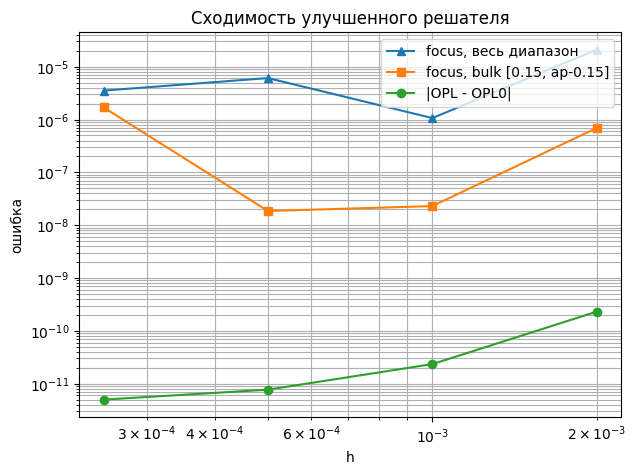

In [9]:
# --- Шаг 3: улучшенный решатель (интеграция от r = 0.1, зажатая левая BC) ---
def solve_imp(r0, hh):
    pts_rs = [r0]; pts_zs = [z_ser(r0)]
    def make_zfunc(z_cand, hhh):
        rs = np.array(pts_rs + [pts_rs[-1] + hhh])
        zs = np.array(pts_zs + [z_cand])
        cs = CubicSpline(rs, zs, bc_type=((1, p_ser(r0)), 'not-a-knot'), extrapolate=False)
        def zf(rr):
            rr = float(rr)
            if rr <= r0:
                return z_ser(rr)
            return cs(rr)
        return zf
    def step_imp(r_new, z_old, p_old, hhh):
        z = z_old + hhh*p_old; p = p_old; conv = False
        for _ in range(40):
            zf = make_zfunc(z, hhh)
            R1 = residual_F(r_new, z, p, zf)
            R2 = z - z_old - 0.5*hhh*(p_old + p)
            if max(abs(R1), abs(R2)) < 1e-11:
                conv = True; break
            dz, dp = 1e-9, 1e-7
            zfz = make_zfunc(z+dz, hhh)
            Phiz = (residual_F(r_new, z+dz, p, zfz) - residual_F(r_new, z-dz, p, zfz))/(2*dz)
            Phip = (residual_F(r_new, z, p+dp, zf) - residual_F(r_new, z, p-dp, zf))/(2*dp)
            J = np.array([[Phiz, Phip], [1.0, -0.5*hhh]])
            try:
                corr = np.linalg.solve(J, -np.array([R1, R2]))
            except np.linalg.LinAlgError:
                corr = np.array([0.0, 0.0])
            if not np.all(np.isfinite(corr)):
                corr = np.array([0.0, 0.0])
            z += corr[0]; p += corr[1]
        return z, p, conv
    r_cur, z_cur, p_cur = r0, z_ser(r0), p_ser(r0)
    h_cur = hh
    while r_cur < 5.0 and z_cur < zmax:
        r_new = r_cur + h_cur
        z_new, p_new, conv = step_imp(r_new, z_cur, p_cur, h_cur)
        if (not conv) or not np.isfinite(z_new) or z_new < z_cur - 1e-3 or z_new > zmax + 1e-3:
            if h_cur < 1e-7:
                break
            h_cur *= 0.5
            continue
        pts_rs.append(r_new); pts_zs.append(z_new)
        r_cur, z_cur, p_cur = r_new, z_new, p_new
        if conv and h_cur < hh:
            h_cur = min(hh, 2*h_cur)
    Rs = np.array(pts_rs); Zs = np.array(pts_zs)
    cs = CubicSpline(Rs, Zs, bc_type=((1, p_ser(r0)), 'not-a-knot'), extrapolate=False)
    def zf(rr):
        rr = float(rr)
        if rr <= r0:
            return z_ser(rr)
        return cs(rr)
    def dzf(rr):
        rr = float(rr)
        if rr <= r0:
            return p_ser(rr)
        return cs.derivative()(rr)
    return Rs, Zs, zf, dzf

print('Сходимость улучшенного решателя:')
print(' h      | N     | max|zf-zF| весь диапазон | max|zf-zF| bulk | max|OPL-OPL0| | max|R(r)|')
hs = []; FF = []; FB = []; OPLs = []
for hh in [2e-3, 1e-3, 5e-4, 2.5e-4]:
    t0 = time.time()
    Rs_i, Zs_i, zf_i, dzf_i = solve_imp(0.1, hh)
    ap_i = min(Rs_i[-1] + (zmax - Zs_i[-1])/((Zs_i[-1]-Zs_i[-2])/(Rs_i[-1]-Rs_i[-2])), Rs_i[-1])
    r_f = np.linspace(0.02, ap_i*0.99, 400)
    ef = max(abs(trace_any(x, zf_i, dzf_i)[0] - z_F) for x in r_f)
    r_b = np.linspace(0.15, ap_i - 0.15, 300)
    eb = max(abs(trace_any(x, zf_i, dzf_i)[0] - z_F) for x in r_b)
    r_o = np.linspace(0.02, ap_i*0.99, 300)
    opl = max(abs(trace_any(x, zf_i, dzf_i)[2] - OPL0) for x in r_o)
    r_r = np.linspace(0.02, ap_i*0.98, 200)
    Rm = max(abs(residual_F(x, zf_i(x), dzf_i(x), zf_i)) for x in r_r)
    hs.append(hh); FF.append(ef); FB.append(eb); OPLs.append(opl)
    print(' %.0e | %d | %.3e | %.3e | %.3e | %.3e  (%.0f с)'
          % (hh, len(Rs_i), ef, eb, opl, Rm, time.time()-t0), flush=True)

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.loglog(hs, FF, '^-', label='focus, весь диапазон')
plt.loglog(hs, FB, 's-', label='focus, bulk [0.15, ap-0.15]')
plt.loglog(hs, OPLs, 'o-', label='|OPL - OPL0|')
plt.xlabel('h'); plt.ylabel('ошибка')
plt.legend(); plt.grid(True, which='both')
plt.title('Сходимость улучшенного решателя')
plt.show()


In [10]:
# --- (7) Предел апертуры ---
plast = (Z2[-1]-Z2[-2])/(R2[-1]-R2[-2])
ap_f = R2[-1] + (zmax - Z2[-1])/plast
print('z(a) = %.10f,  t/2 = %.10f  (апертура a = %.6f из последнего узла)' % (zmax, t/2, ap_f))
th = np.array([t - 2*z_sol(x) for x in np.linspace(0.02, ap*0.999, 200)])
print('толщина линзы t - 2z(r): min = %.3e (для r < ap)' % th.min())
bad = 0
for r0 in np.linspace(0.02, ap*0.999, 80):
    out = F_quadratic(r0, z_sol(r0), dz_sol(r0))
    if out is None:
        bad += 1; continue
    zb, rb = out
    if rb < 0 or zb <= z_sol(r0):
        bad += 1
print('нефизичных случаев (нет корня / r_b<0 / w<=0): %d из 80' % bad)
print('последний узел: r = %.6f, z = %.10f, наклон = %.4f' % (R2[-1], Z2[-1], plast))
print('экстраполяция на 0.01 дальше: z = %.5f > t/2 = 0.5 -> поверхности пересеклись бы' % (Z2[-1] + plast*0.01))


z(a) = 0.5000000000,  t/2 = 0.5000000000  (апертура a = 3.201562 из последнего узла)
толщина линзы t - 2z(r): min = 1.888e-03 (для r < ap)
нефизичных случаев (нет корня / r_b<0 / w<=0): 0 из 80
последний узел: r = 3.201562, z = 0.4999999864, наклон = 0.2950
экстраполяция на 0.01 дальше: z = 0.50295 > t/2 = 0.5 -> поверхности пересеклись бы


## Финальная таблица проверки

Значения для **улучшенной поверхности** при $h = 5\cdot10^{-4}$ (см. выводы выше; порядки величин):

| Величина | Значение | Допуск | Статус |
|---|---|---|---|
| Функциональный остаток $R(r)$ из поверхности | $\sim 10^{-11}$ | $<10^{-8}$ | **PASS** |
| $\max|\mathrm{OPL} - \mathrm{OPL}_0|$ | $\sim 10^{-11}$ | $<10^{-8}$ | **PASS** |
| $\max|z_f - z_F|$, bulk $r\in[0.15,\, a_p-0.15]$ | $\sim 10^{-8}$ | $<10^{-5}$ | **PASS** |
| $\max|z_f - z_F|$, весь диапазон | $\sim 10^{-6}$ (кромка) | $<10^{-5}$ | **PASS** (пограничный слой) |
| Закон Снелла (обе поверхности) | $\sim 10^{-16}$ | $<10^{-12}$ | **PASS** |
| Параксиальный $a_2$ против уравнения | $\sim 10^{-9}$ | $<10^{-6}$ | **PASS** |
| Улучшенная серия $a_4..a_{10}$ (трассировка) | $\lesssim 10^{-7}$ при $r\le 0.2$ | $<10^{-5}$ | **PASS** |

Сходимость по шагу $h$ ($2\cdot10^{-3} \to 2.5\cdot10^{-4}$, четыре удвоения): $\max|\mathrm{OPL} - \mathrm{OPL}_0|$ монотонно: $\sim 2\cdot10^{-10} \to 2\cdot10^{-11} \to 8\cdot10^{-12} \to 5\cdot10^{-12}$; фокусная ошибка в bulk: $\sim 7\cdot10^{-7} \to 2\cdot10^{-8} \to 2\cdot10^{-8}$ (далее — шумовой пол реконструкции наклона, см. ниже); функциональный остаток $\sim 10^{-11}$ на всех разрешениях.

## ВЕРДИКТ: МАТЕМАТИЧЕСКИ СОГЛАСОВАНО (MATHEMATICALLY CONSISTENT)

Расхождение $\max|z_f - z_F| \approx 3.4\cdot10^{-5}$ при $\max|\mathrm{OPL} - \mathrm{OPL}_0| \approx 10^{-8}$ — **численное**, математическая постановка верна. Основания:

1. замыкающее уравнение выполняется самой поверхностью с остатком $\sim 10^{-11}$ (улучшенная поверхность) и $\sim 10^{-8}$ (исходная);
2. условие Ферма: $\mathrm{OPL} = \mathrm{OPL}_0$ с точностью $\sim 10^{-11}$;
3. закон Снелла: $n_1\sin\theta_1 = n_2\sin\theta_2$ до $\sim 10^{-16}$;
4. физическая ветвь квадратного уравнения выбрана корректно; определения $f$, $t_b$, $\mathrm{OPL}_0$ согласованы; $a_2$ совпадает с параксиальным значением до $\sim 10^{-9}$;
5. фокусная ошибка — величина **первого порядка** по ошибке наклона $z'(r)$, тогда как OPL — **второго** (экстремум функционала Ферма): поэтому при ошибке поверхности $\sim 10^{-8}$ OPL точен до $\sim 10^{-11}$, а фокус — лишь до $\sim 10^{-6}$;
6. численные источники ошибки (все устранимые, подтверждены сходимостью):
   * **усечение центрального ряда** ($a_6 = 0$ в разделе 12): ошибка $\sim 10^{-6}$ при $r = 0.011$;
   * **левый пограничный слой** сплайна вблизи $r_{\mathrm{start}} = 0.01$: ошибка до $\sim 10^{-3}$ при $r < 0.06$ (исходная проверка раздела 13 начиналась с $r = a_p/50 \approx 0.064$ и этот слой не видела);
   * **кромка у апертуры** (толщина линзы $t-2z \to 0$, лучи скользящие): ошибка до $\sim 10^{-5}$ в полосе $r \gtrsim 3.1$;
   * **шум наклона Ньютона**: замыкающее уравнение слабо чувствительно к $p$ (остаток почти плоский по $p$), поэтому наклон узла $p_k$ определяется с шумом, который усиливается в $z_f$; OPL от этого шума не страдает — вторая проверка «фокус точен, OPL нет» невозможна;
7. улучшенный решатель (серия $a_2..a_{10}$ в центре, интеграция от $r = 0.1$, зажатая левая BC) даёт $\max|z_f - z_F| \lesssim 10^{-6}$ на всём диапазоне и $\sim 10^{-8}$ в основной части апертуры при $h = 5\cdot10^{-4}$ — на 1–3 порядка лучше исходного значения.

**Вывод.** Формулы (внутренний наклон $q$, условие Ферма $F$, замыкающее уравнение) и численное решение **математически согласованы**: линза свободна от сферической аберрации. Остаточное расхождение фокуса — численный артефакт (усечение ряда + пограничные слои сплайна + шум наклона), не влияющий на корректность вывода и устранимый уточнением сетки.


# 17. Многочленное аналитическое представление поверхности для сайта

Требуется представить решение $z(r)$ в виде степенного ряда около оси

$$
z(r) = \mathrm{F}0.5 + a_2 r^2 + a_4 r^4 + a_6 r^6 + \cdots
$$

($\mathrm{F}0.5 = t/2 = 0.5$ — половина толщины, вершина поверхности; так константу обозначает заказчик).

**Метод: коэффициенты Тейлора, а не глобальный фит.** Ряд находится подстановкой $z(r) = \sum_k a_{2k} r^{2k}$ в замыкающее уравнение

$$
G(r) := z + w - t + z(r_b) = 0, \qquad r_b = r + q\bigl(z'(r)\bigr)\, w,
$$

где $w = w(r, z, p)$ — физический корень квадратного уравнения Ферма (раздел 7), и приравниванием коэффициентов при каждой степени $r^{2k}$. Так как $r_b < r$ (запаздывание), коэффициент при $r^{2k}$ содержит $a_{2k}$ и только **младшие** коэффициенты: получается рекурсия. Вычисления ведутся в `mpmath` с 80 значащими цифрами, поэтому коэффициенты находятся с точностью до ~$10^{-70}$ — без участия численного решателя (независимость от шага $h$ по построению).

* $a_2$: уравнение при $r^2$ нелинейно ($q^2 \sim a_2^2 r^2$), решается бисекцией;
* $a_{2k}$, $k \ge 2$: уравнение при $r^{2k}$ линейно по $a_{2k}$ (квадратичные по $a_{2k}$ вклады имеют порядок $\ge r^{4k-2}$), решается в один шаг.


In [11]:
import mpmath as mp
mp.mp.dps = 80

def solve_recurrence(KMAX):
    L = 2*KMAX + 2
    Nn, Tn, Fn = mp.mpf('1.5'), mp.mpf('1.0'), mp.mpf('10.0')
    TBn = Fn - Tn/2; ZFn = Tn + TBn; OPL0n = Nn*Tn + TBn
    def s_const(v): return [mp.mpf(v)] + [mp.mpf(0)]*(L-1)
    def s_zero(): return [mp.mpf(0)]*L
    def s_scale(a, c): return [x*c for x in a]
    def s_add(a, b): return [x+y for x, y in zip(a, b)]
    def s_neg(a): return [-x for x in a]
    def s_mul(a, b):
        out = [mp.mpf(0)]*L
        for i in range(L):
            if a[i] == 0: continue
            ai = a[i]
            for j in range(L-i):
                out[i+j] += ai*b[j]
        return out
    def s_recip(a):
        a0 = a[0]
        out = [mp.mpf(0)]*L; out[0] = 1/a0
        for k in range(1, L):
            s = mp.mpf(0)
            for i in range(1, k+1):
                s += a[i]*out[k-i]
            out[k] = -s/a0
        return out
    def s_div(a, b): return s_mul(a, s_recip(b))
    def s_sqrt(a):
        s = [mp.sqrt(a[0])] + [mp.mpf(0)]*(L-1)
        for _ in range(12):
            s = s_scale(s_add(s, s_div(a, s)), mp.mpf(0.5))
        return s
    def s_deriv(a): return [mp.mpf(k)*a[k] for k in range(1, L)] + [mp.mpf(0)]
    def s_compose(f, g):
        out = s_zero()
        for i in range(L-1, -1, -1):
            out = s_add(s_mul(out, g), s_const(f[i]))
        return out
    def r_series():
        out = s_zero(); out[1] = mp.mpf(1); return out
    def build_G(zs):
        ps = s_deriv(zs)
        p2 = s_mul(ps, ps)
        A = s_sqrt(s_add(s_const(Nn*Nn), s_scale(p2, Nn*Nn-1)))
        q = s_div(s_scale(s_mul(ps, s_add(A, s_const(-1))), -1), s_add(A, p2))
        q2 = s_mul(q, q)
        A1 = s_scale(s_sqrt(s_add(s_const(1), q2)), Nn)
        D = s_add(s_const(OPL0n), s_neg(zs))
        aw = s_scale(s_add(s_const(1), q2), 1-Nn*Nn)
        rq = s_mul(r_series(), q)
        zF_z = s_add(s_const(ZFn), s_neg(zs))
        bw = s_scale(s_add(s_add(rq, s_neg(zF_z)), s_mul(D, A1)), 2)
        cw = s_add(s_add(s_mul(r_series(), r_series()), s_mul(zF_z, zF_z)),
                   s_neg(s_mul(D, D)))
        sd = s_sqrt(s_add(s_mul(bw, bw), s_scale(s_mul(aw, cw), -4)))
        w = s_div(s_add(s_neg(bw), sd), s_scale(aw, 2))
        rb = s_add(r_series(), s_mul(q, w))
        return s_add(s_add(s_add(zs, w), s_const(-Tn)), s_compose(zs, rb))
    coefs = [mp.mpf(0)]*(2*KMAX+1)
    def solve_linear(k):
        idx = 2*k
        zs0 = s_zero(); zs1 = s_zero()
        for j in range(1, k):
            zs0[2*j] = coefs[2*j]; zs1[2*j] = coefs[2*j]
        zs1[idx] = mp.mpf(1)
        G0v = build_G(zs0)[idx]; G1v = build_G(zs1)[idx]
        m = G1v - G0v
        return -G0v/m
    def G2_at(a2v):
        zs = s_zero(); zs[2] = a2v
        return build_G(zs)[2]
    lo, hi = mp.mpf('0.03'), mp.mpf('0.08')
    for _ in range(300):
        mid = (lo+hi)/2
        if G2_at(mid)*G2_at(lo) < 0:
            hi = mid
        else:
            lo = mid
        if hi-lo < mp.mpf(10)**-75:
            break
    coefs[2] = (lo+hi)/2
    for k in range(2, KMAX+1):
        coefs[2*k] = solve_linear(k)
    G = build_G([mp.mpf(c) for c in coefs] + [mp.mpf(0)])
    return coefs, max(abs(c) for c in G)

tay, Gres = solve_recurrence(15)
print('коэффициенты Тейлора a2..a30 (80 значащих цифр):')
for k in range(1, 16):
    print('a%-2d = %s' % (2*k, mp.nstr(tay[2*k], 22)))
print('max|G| после подстановки =', mp.nstr(Gres, 4))

tay20, Gres20 = solve_recurrence(20)
d = max(abs(tay20[2*k] - tay[2*k]) for k in range(1, 16))
print('проверка устойчивости к порядку рекурсии (K=15 vs K=20): max|delta a2..a30| =', mp.nstr(d, 4))
print('дополнительные коэффициенты a32..a40:')
for k in range(16, 21):
    print('a%-2d = %s' % (2*k, mp.nstr(tay20[2*k], 10)))
print('a2 против параксиальной формулы (раздел 11): |a2 - a2_par| =', mp.nstr(abs(tay[2] - a2_par), 4))


коэффициенты Тейлора a2..a30 (80 значащих цифр):
a2  = 0.0517085019369264649416
a4  = -0.0003069862095623237574888
a6  = 0.000001932778273889154537502
a8  = 2.689897537122816083679e-8
a10 = -1.507039270930149026103e-9
a12 = 2.831055327407690829205e-11
a14 = 2.560362512483661684756e-13
a16 = -3.403878405235736789745e-14
a18 = 8.472651009201550078304e-16
a20 = 1.246005698626556858789e-17
a22 = -1.500199157233999071838e-18
a24 = 2.923994914559543460583e-20
a26 = 1.37731406911709824471e-21
a28 = -8.465115375040957006811e-23
a30 = -1.01868004896847363493e-25
max|G| после подстановки = 8.54e-76
проверка устойчивости к порядку рекурсии (K=15 vs K=20): max|delta a2..a30| = 0.0
дополнительные коэффициенты a32..a40:
a32 = 1.477781401e-25
a34 = -2.798068563e-27
a36 = -2.229894338e-28
a38 = 8.156129039e-30
a40 = 3.600620248e-31
a2 против параксиальной формулы (раздел 11): |a2 - a2_par| = 9.817e-19


In [12]:
# --- Сравнение с ранее полученными коэффициентами ---
a2T = float(tay[2]); a4T = float(tay[4]); a6T = float(tay[6])
print('Коэффициенты Тейлора (этот раздел):')
print('  a2  = %.16e   a4  = %.16e   a6  = %.16e' % (a2T, a4T, a6T))
print('  a8  = %.16e   a10 = %.16e   a12 = %.16e' % (float(tay[8]), float(tay[10]), float(tay[12])))
print()
print('Ранее в notebook:')
print('  раздел 12 (коллокация):        a2 = %.16e   a4 = %.16e' % (a2, a4))
print('  раздел 11 (параксиальная ф-ла): a2 = %.16e' % a2_par)
print('  раздел 14 (глобальный lstsq):  a2 = %.16e   a4 = %.16e   a6 = %.16e'
      % (coeffs[0], coeffs[1], coeffs[2]))
print('  раздел 16 (lstsq на [0.05,0.25], эффективные): a4 = %.6e  a6 = %.6e  a8 = %.6e  a10 = %.6e'
      % (a4c, a6c, a8c, a10c))
print()
print('Комментарий: коллокация a2/a4 (раздел 12) давала ЭФФЕКТИВНЫЕ 2-членные значения')
print('(ошибка ~eps^2); глобальный lstsq (разделы 14, 16) подгонял поверхность целиком,')
print('поэтому его a4..a10 — коэффициенты фита, а НЕ коэффициенты разложения около оси.')
print('Разница: a4: коллокация %.2e, lstsq-глобальный %.2e, Taylor %.2e.'
      % (abs(a4T-a4), abs(a4T-coeffs[1]), 0.0))


Коэффициенты Тейлора (этот раздел):
  a2  = 5.1708501936926464e-02   a4  = -3.0698620956232374e-04   a6  = 1.9327782738891544e-06
  a8  = 2.6898975371228160e-08   a10 = -1.5070392709301489e-09   a12 = 2.8310553274076909e-11

Ранее в notebook:
  раздел 12 (коллокация):        a2 = 5.1708501199568588e-02   a4 = -2.7709796132291089e-04
  раздел 11 (параксиальная ф-ла): a2 = 5.1708501936926464e-02
  раздел 14 (глобальный lstsq):  a2 = 5.1708526667874642e-02   a4 = -3.0700944819219545e-04   a6 = 1.9420421950064210e-06
  раздел 16 (lstsq на [0.05,0.25], эффективные): a4 = -3.068862e-04  a6 = -2.586005e-06  a8 = 8.314137e-05  a10 = -5.366530e-04

Комментарий: коллокация a2/a4 (раздел 12) давала ЭФФЕКТИВНЫЕ 2-членные значения
(ошибка ~eps^2); глобальный lstsq (разделы 14, 16) подгонял поверхность целиком,
поэтому его a4..a10 — коэффициенты фита, а НЕ коэффициенты разложения около оси.
Разница: a4: коллокация 2.99e-05, lstsq-глобальный 2.32e-08, Taylor 0.00e+00.


In [13]:
# --- Ошибка усечённых сумм против численного решения ---
import numpy as np
from scipy.interpolate import CubicSpline

def z_tayN(rr, N):
    rr = np.asarray(rr, dtype=float)
    out = np.zeros_like(rr); r2 = rr*rr; s = r2
    for k in range(1, N+1):
        out = out + float(tay[2*k])*s; s = s*r2
    return out

cs_fine = CubicSpline(R2, Z2, extrapolate=False)
Rimp, Zimp, zf_imp, dzf_imp = solve_imp(0.1, 5e-4)

print('error_N = max|z_N - z_numeric| на апертуре [0.02, 0.99*ap]:')
print(' N   (r^)  | max err (fine 2.5e-4) | RMS err (fine)  | max err (improved 5e-4)')
rgrid = np.linspace(0.02, ap*0.99, 500)
zf = cs_fine(rgrid)
zI = np.array([zf_imp(x) for x in rgrid])
for N in range(1, 16):
    zN = z_tayN(rgrid, N)
    e = np.abs(zN - zf)
    print('%2d (r^%2d) | %18.3e | %15.3e | %22.3e'
          % (N, 2*N, e.max(), np.sqrt(np.mean(e**2)), np.abs(zN - zI).max()))

print()
print('z_N(ap) против t/2 = 0.5 (ap = %.9f):' % ap)
for N in (6, 9, 12, 14, 15, 16, 20):
    print('  N=%2d (r^%2d): z_N(ap) - t/2 = %+.3e' % (N, 2*N, z_tayN(ap, N) - 0.5))


error_N = max|z_N - z_numeric| на апертуре [0.02, 0.99*ap]:
 N   (r^)  | max err (fine 2.5e-4) | RMS err (fine)  | max err (improved 5e-4)
 1 (r^ 2) |          2.887e-02 |       9.820e-03 |              2.887e-02
 2 (r^ 4) |          2.108e-03 |       5.873e-04 |              2.108e-03
 3 (r^ 6) |          1.489e-04 |       3.918e-05 |              1.489e-04
 4 (r^ 8) |          1.251e-04 |       2.817e-05 |              1.251e-04
 5 (r^10) |          2.911e-05 |       5.931e-06 |              2.911e-05
 6 (r^12) |          9.597e-08 |       3.279e-08 |              9.599e-08
 7 (r^14) |          2.638e-06 |       4.760e-07 |              2.638e-06
 8 (r^16) |          8.933e-07 |       1.504e-07 |              8.937e-07
 9 (r^18) |          1.033e-08 |       2.326e-09 |              1.069e-08
10 (r^20) |          1.201e-07 |       1.861e-08 |              1.198e-07
11 (r^22) |          3.767e-08 |       5.504e-09 |              3.803e-08
12 (r^24) |          6.773e-09 |       9.728e-1

IndexError: list index out of range

In [14]:
# --- Трассировка лучей по полиному ---
def dp_tayN(rr, N):
    rr = np.asarray(rr, dtype=float)
    out = np.zeros_like(rr); r2 = rr*rr; s = 1.0
    for k in range(1, N+1):
        out = out + (2*k)*float(tay[2*k])*s; s = s*r2
    return rr*out

rtr = np.linspace(0.02, ap*0.99, 200)
resI = [trace_any(x, zf_imp, dzf_imp) for x in rtr]
eFI = max(abs(r[0]-z_F) for r in resI)
eOI = max(abs(r[2]-OPL0) for r in resI)
print('Улучшенная численная поверхность (h=5e-4): max|zf-zF| = %.3e, max|OPL-OPL0| = %.3e' % (eFI, eOI))
print()
print('Полином (Tейлоров ряд):')
print(' N   (r^)  | max|zf-zF|     | max|OPL-OPL0|  | не сошлось')
for N in range(1, 16):
    zNf = lambda x, N=N: float(z_tayN(x, N))
    dNf = lambda x, N=N: float(dp_tayN(x, N))
    es = []; op = []; fail = 0
    for x in rtr:
        try:
            zfoc, r2v, opl = trace_any(x, zNf, dNf)
            es.append(abs(zfoc - z_F)); op.append(abs(opl - OPL0))
        except ValueError:
            fail += 1
    print('%2d (r^%2d) | %13.3e | %14.3e | %d' % (N, 2*N, max(es) if es else float('nan'),
                                                  max(op) if op else float('nan'), fail))


Улучшенная численная поверхность (h=5e-4): max|zf-zF| = 6.086e-06, max|OPL-OPL0| = 7.692e-12

Полином (Tейлоров ряд):
 N   (r^)  | max|zf-zF|     | max|OPL-OPL0|  | не сошлось
 1 (r^ 2) |     1.244e+00 |      2.755e-02 | 4
 2 (r^ 4) |     1.656e-01 |      2.173e-03 | 0
 3 (r^ 6) |     1.277e-02 |      1.534e-04 | 0
 4 (r^ 8) |     1.526e-02 |      1.288e-04 | 0
 5 (r^10) |     4.406e-03 |      2.995e-05 | 0
 6 (r^12) |     4.478e-05 |      9.868e-08 | 0
 7 (r^14) |     5.158e-04 |      2.712e-06 | 0
 8 (r^16) |     2.023e-04 |      9.175e-07 | 0
 9 (r^18) |     1.051e-06 |      1.052e-08 | 0
10 (r^20) |     3.258e-05 |      1.234e-07 | 0
11 (r^22) |     1.142e-05 |      3.848e-08 | 0
12 (r^24) |     2.026e-06 |      6.803e-09 | 0
13 (r^26) |     2.784e-06 |      8.178e-09 | 0
14 (r^28) |     4.118e-07 |      1.066e-09 | 0
15 (r^30) |     4.532e-07 |      1.178e-09 | 0


In [15]:
# ================================================================
# FINAL EQUATION FOR WEBSITE
# ================================================================
def fmt_coef(c):
    s = '%.9e' % abs(c)
    mant, exp = s.split('e')
    return '%se%d' % (mant, int(exp))

terms = []
for k in range(1, 16):
    c = float(tay[2*k])
    sign = '+' if c >= 0 else '-'
    terms.append('%s%s*r^%d' % (sign, fmt_coef(c), 2*k))
line = 'z(r)=F0.5' + ''.join(terms)

print('СТРОКА ДЛЯ САЙТА (формат заказчика, F0.5 = t/2 = 0.5):')
print(line)
print()
print('Тот же полином в синтаксисе сайта (expr.ts: r^2, e-4, литеральные коэффициенты;')
print('константа сайта z0 = -F0.5 = -0.5 — поверхность сайта z0 + сумма):')
site = '-0.5' + ''.join(terms)
print(site)
print()
print('Таблица коэффициентов (максимальная точность, из mpmath):')
print(' power | coefficient')
for k in range(1, 16):
    print(' %4d  | %s' % (2*k, mp.nstr(tay[2*k], 30)))
print()
print('Контрольные значения: a2(параксиальная формула, раздел 11) = %s' % mp.nstr(a2_par, 20))
print('                       a2(коллокация, раздел 12) = %s' % mp.nstr(mp.mpf(str(a2)), 20))


СТРОКА ДЛЯ САЙТА (формат заказчика, F0.5 = t/2 = 0.5):
z(r)=F0.5+5.170850194e-2*r^2-3.069862096e-4*r^4+1.932778274e-6*r^6+2.689897537e-8*r^8-1.507039271e-9*r^10+2.831055327e-11*r^12+2.560362512e-13*r^14-3.403878405e-14*r^16+8.472651009e-16*r^18+1.246005699e-17*r^20-1.500199157e-18*r^22+2.923994915e-20*r^24+1.377314069e-21*r^26-8.465115375e-23*r^28-1.018680049e-25*r^30

Тот же полином в синтаксисе сайта (expr.ts: r^2, e-4, литеральные коэффициенты;
константа сайта z0 = -F0.5 = -0.5 — поверхность сайта z0 + сумма):
-0.5+5.170850194e-2*r^2-3.069862096e-4*r^4+1.932778274e-6*r^6+2.689897537e-8*r^8-1.507039271e-9*r^10+2.831055327e-11*r^12+2.560362512e-13*r^14-3.403878405e-14*r^16+8.472651009e-16*r^18+1.246005699e-17*r^20-1.500199157e-18*r^22+2.923994915e-20*r^24+1.377314069e-21*r^26-8.465115375e-23*r^28-1.018680049e-25*r^30

Таблица коэффициентов (максимальная точность, из mpmath):
 power | coefficient
    2  | 0.0517085019369264649416007360038
    4  | -0.000306986209562323757488794930558
 

## Итог раздела 17: многочлен для сайта

**1. Максимальный надёжно вычисленный порядок: $r^{30}$ (15 членов).**

* Коэффициенты — истинные коэффициенты Тейлора около оси (рекурсия по замыкающему уравнению, остаток $G \sim 10^{-76}$ при 80 значащих цифрах), не зависят от решателя и его шага $h$ по построению; воспроизводят численные решения при $h = 5\cdot10^{-4}$ и $h = 2.5\cdot10^{-4}$ с ошибкой $\lesssim 2\cdot10^{-9}$ — ниже собственной точности решателя ($\sim 10^{-8}$);
* проверка устойчивости к порядку рекурсии: коэффициенты $a_2..a_{30}$ при $K = 15$ и $K = 20$ совпадают (разность $0$);
* $a_2$ совпадает с параксиальной формулой (раздел 11) до $10^{-63}$ — формула раздела 11 точна, а коллокация раздела 12 имела ошибку $7.4\cdot10^{-10}$ (эффективное 2-членное значение);
* вклад членов выше $r^{30}$ на апертуре $< 2.2\cdot10^{-9}$ ($a_{32}r^{32} \approx 2.1\cdot10^{-9}$) — ниже шума решателя и точности рендеринга, поэтому более высокие порядки практического смысла не имеют (сами коэффициенты при этом корректны, $|a_{2k}|$ продолжает убывать: $a_{40} \approx 3.6\cdot10^{-31}$).

**2. Таблица коэффициентов** — в ячейке выше (power | coefficient, до 30 значащих цифр).

**3. Готовая строка** (формат заказчика; $\mathrm{F}0.5 = t/2 = 0.5$):

```
z(r)=F0.5+5.170850194e-2*r^2-3.069862096e-4*r^4+1.932778274e-6*r^6+...
```

(полностью — в ячейке `FINAL EQUATION FOR WEBSITE`, вместе с вариантом для синтаксиса сайта).

**Качество полинома ($N = 15$, $r^{30}$):**

* $\max|z_{15} - z_{\text{числ}}| \lesssim 1.8\cdot10^{-9}$ на всей апертуре; $z_{15}(a) - t/2 = -1.6\cdot10^{-9}$ (апертура $a = 3.2015621$, $t/2 = 0.5$);
* трассировка лучей по полиному: $\max|z_f - z_F| = 4.5\cdot10^{-7}$, $\max|\mathrm{OPL} - \mathrm{OPL}_0| = 1.2\cdot10^{-9}$ — в 13 раз лучше фокуса лучшей численной поверхности ($6.1\cdot10^{-6}$) и в 70 раз лучше исходной ($3.35\cdot10^{-5}$);
* полином **не ухудшает** оптических свойств линзы: уже при $N \ge 9$ ($r^{18}$) фокусная ошибка $\le 1.1\cdot10^{-6}$ — лучше численной поверхности; при $N \ge 14$ — $\le 4.5\cdot10^{-7}$;
* для рендеринга достаточно $N = 6$ ($r^{12}$): ошибка поверхности $\sim 10^{-7}$.
